Using device: cuda

--- Training with Adam Optimizer (Paper Setup) ---
Adam Epoch    0 | Loss: 9.15981e-01
Adam Epoch  200 | Loss: 6.18849e-02
Adam Epoch  400 | Loss: 5.42012e-02
Adam Epoch  600 | Loss: 4.88724e-02
Adam Epoch  800 | Loss: 4.85058e-02
Adam Epoch 1000 | Loss: 4.11054e-02
Adam Epoch 1200 | Loss: 3.93289e-02
Adam Epoch 1400 | Loss: 3.55879e-02
Adam Epoch 1600 | Loss: 5.59542e-02
Adam Epoch 1800 | Loss: 3.71972e-02
Adam Epoch 1999 | Loss: 5.56071e-02

--- Training with L-BFGS Optimizer (High-Precision Refinement) ---
L-BFGS Iteration   50 | Loss: 2.86990e-02
L-BFGS Iteration  100 | Loss: 2.42336e-02
L-BFGS Iteration  150 | Loss: 2.06239e-02
L-BFGS Iteration  200 | Loss: 1.76528e-02
L-BFGS Iteration  250 | Loss: 1.55197e-02
L-BFGS Iteration  300 | Loss: 1.39277e-02
L-BFGS Iteration  350 | Loss: 1.25348e-02
L-BFGS Iteration  400 | Loss: 1.09264e-02
L-BFGS Iteration  450 | Loss: 9.53403e-03
L-BFGS Iteration  500 | Loss: 8.57331e-03
L-BFGS Iteration  550 | Loss: 7.55271e-03
L-B

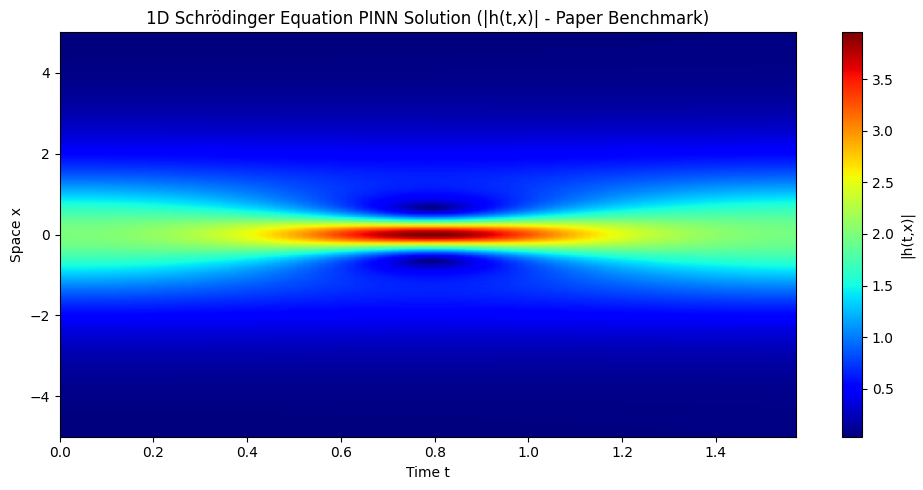

In [11]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
torch.manual_seed(1234)
np.random.seed(1234)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

class DNN(nn.Module):
    def __init__(self, layers):
        super(DNN, self).__init__()
        hidden_layers = []
        for i in range(len(layers) - 2):
            hidden_layers.append(nn.Linear(layers[i], layers[i+1]))
            hidden_layers.append(nn.Tanh())
        hidden_layers.append(nn.Linear(layers[-2], layers[-1]))
        self.net = nn.Sequential(*hidden_layers)

    def forward(self, t, x):
        inputs = torch.cat([t, x], dim=1)
        return self.net(inputs) # Returns [u, v]

class SchrödingerPINN:
    def __init__(self, X_u, u_train, v_train, X_f, X_b, layers):
        # Initial condition tensors
        self.t_u = X_u[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_u = X_u[:, 1:2].clone().detach().requires_grad_(True).to(device)
        self.u_train = u_train.to(device)
        self.v_train = v_train.to(device)

        # Collocation points tensors (for PDE residuals)
        self.t_f = X_f[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_f = X_f[:, 1:2].clone().detach().requires_grad_(True).to(device)

        # Periodic boundary time tensors
        self.t_b = X_b[:, 0:1].clone().detach().requires_grad_(True).to(device)
        self.x_lb = torch.full_like(self.t_b, -5.0).requires_grad_(True).to(device)
        self.x_ub = torch.full_like(self.t_b, 5.0).requires_grad_(True).to(device)

        self.dnn = DNN(layers).to(device)

        # Optimizers following paper strategy: Adam followed by L-BFGS
        self.optimizer_Adam = torch.optim.Adam(self.dnn.parameters(), lr=1e-3)
        self.optimizer_LBFGS = torch.optim.LBFGS(
            self.dnn.parameters(),
            lr=1.0,
            max_iter=5000,
            max_eval=5000,
            history_size=50,
            line_search_fn='strong_wolfe'
        )

    def net_uv(self, t, x):
        uv = self.dnn(t, x)
        u = uv[:, 0:1]
        v = uv[:, 1:2]
        return u, v

    def net_f(self, t, x):
        u, v = self.net_uv(t, x)

        # Exact automatic differentiation for NLS derivatives
        u_t = torch.autograd.grad(u, t, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
        u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]

        v_t = torch.autograd.grad(v, t, grad_outputs=torch.ones_like(v), create_graph=True)[0]
        v_x = torch.autograd.grad(v, x, grad_outputs=torch.ones_like(v), create_graph=True)[0]
        v_xx = torch.autograd.grad(v_x, x, grad_outputs=torch.ones_like(v_x), create_graph=True)[0]

        # Coupled NLS Residuals:
        # f_u = u_t + 0.5 * v_xx + v * (u^2 + v^2)
        # f_v = v_t - 0.5 * u_xx - u * (u^2 + v^2)
        f_u = u_t + 0.5 * v_xx + v * (u**2 + v**2)
        f_v = v_t - 0.5 * u_xx - u * (u**2 + v**2)

        return f_u, f_v

    def loss_fn(self):
        # 1. Initial condition loss
        u_pred, v_pred = self.net_uv(self.t_u, self.x_u)
        loss_u = torch.mean((u_pred - self.u_train)**2) + torch.mean((v_pred - self.v_train)**2)

        # 2. PDE collocation loss
        f_u_pred, f_v_pred = self.net_f(self.t_f, self.x_f)
        loss_f = torch.mean(f_u_pred**2) + torch.mean(f_v_pred**2)

        # 3. Periodic boundary loss (u, v and their spatial derivatives match at x=-5 and x=5)
        u_lb, v_lb = self.net_uv(self.t_b, self.x_lb)
        u_ub, v_ub = self.net_uv(self.t_b, self.x_ub)

        u_lb_x = torch.autograd.grad(u_lb, self.x_lb, grad_outputs=torch.ones_like(u_lb), create_graph=True)[0]
        u_ub_x = torch.autograd.grad(u_ub, self.x_ub, grad_outputs=torch.ones_like(u_ub), create_graph=True)[0]
        v_lb_x = torch.autograd.grad(v_lb, self.x_lb, grad_outputs=torch.ones_like(v_lb), create_graph=True)[0]
        v_ub_x = torch.autograd.grad(v_ub, self.x_ub, grad_outputs=torch.ones_like(v_ub), create_graph=True)[0]

        loss_b = torch.mean((u_lb - u_ub)**2) + torch.mean((v_lb - v_ub)**2) + \
                 torch.mean((u_lb_x - u_ub_x)**2) + torch.mean((v_lb_x - v_ub_x)**2)

        return loss_u + loss_f + loss_b

    def train(self, adam_epochs=2000):
        self.dnn.train()
        print("\n--- Training with Adam Optimizer (Paper Setup) ---")
        for epoch in range(adam_epochs):
            self.optimizer_Adam.zero_grad()
            loss = self.loss_fn()
            loss.backward()
            self.optimizer_Adam.step()

            if epoch % 200 == 0 or epoch == adam_epochs - 1:
                print(f"Adam Epoch {epoch:4d} | Loss: {loss.item():.5e}")

        print("\n--- Training with L-BFGS Optimizer (High-Precision Refinement) ---")
        iter_count = [0]
        def closure():
            self.optimizer_LBFGS.zero_grad()
            loss = self.loss_fn()
            loss.backward()
            iter_count[0] += 1
            if iter_count[0] % 50 == 0:
                print(f"L-BFGS Iteration {iter_count[0]:4d} | Loss: {loss.item():.5e}")
            return loss

        self.optimizer_LBFGS.step(closure)

    def predict(self, X_star):
        self.dnn.eval()
        t = torch.tensor(X_star[:, 0:1], dtype=torch.float32, device=device)
        x = torch.tensor(X_star[:, 1:2], dtype=torch.float32, device=device)
        u, v = self.net_uv(t, x)
        h_mag = torch.sqrt(u**2 + v**2) # Magnitude |h(t,x)|
        return h_mag.detach().cpu().numpy()

if __name__ == "__main__":
    # Paper architecture: [2, 100, 100, 100, 100, 100, 2]
    layers = [2, 100, 100, 100, 100, 100, 2]

    # Paper Dataset configuration
    N0 = 50      # Initial condition points
    N_b = 50     # Boundary condition points
    N_f = 20000  # Collocation points inside domain

    # 1. Initial Data Setup (t = 0, x in [-5, 5])
    x0 = np.linspace(-5, 5, N0)[:, None]
    t0 = np.zeros_like(x0)
    u0 = 2.0 / np.cosh(x0)
    v0 = np.zeros_like(x0)

    X_u_train = np.hstack((t0, x0))
    u_train = u0
    v_train = v0

    # 2. Collocation Points Setup (Uniform random sampling across domain)
    t_f = np.random.uniform(0.0, np.pi/2, (N_f, 1))
    x_f = np.random.uniform(-5.0, 5.0, (N_f, 1))
    X_f_train = np.hstack((t_f, x_f))

    # 3. Boundary Points Setup (Time values for periodic boundaries)
    t_b = np.random.uniform(0.0, np.pi/2, (N_b, 1))
    X_b_train = t_b

    # Convert to Tensors
    X_u_tensor = torch.tensor(X_u_train, dtype=torch.float32)
    u_tensor = torch.tensor(u_train, dtype=torch.float32)
    v_tensor = torch.tensor(v_train, dtype=torch.float32)
    X_f_tensor = torch.tensor(X_f_train, dtype=torch.float32)
    X_b_tensor = torch.tensor(X_b_train, dtype=torch.float32)

    # 4. Initialize and Train Model according to paper setup
    pinn = SchrödingerPINN(X_u_tensor, u_tensor, v_tensor, X_f_tensor, X_b_tensor, layers)
    pinn.train(adam_epochs=2000)

    # 5. Grid Generation & Plotting Spatio-Temporal Heatmap (|h(t,x)|)
    n_t, n_x = 100, 256
    t_star = np.linspace(0, np.pi/2, n_t)
    x_star = np.linspace(-5.0, 5.0, n_x)
    T, X = np.meshgrid(t_star, x_star)
    X_star = np.hstack((T.flatten()[:, None], X.flatten()[:, None]))

    H_pred = pinn.predict(X_star).reshape(n_x, n_t)

    plt.figure(figsize=(10, 5))
    plt.imshow(H_pred, extent=[0, np.pi/2, -5, 5], origin='lower', aspect='auto', cmap='jet')
    plt.colorbar(label='|h(t,x)|')
    plt.title('1D Schrödinger Equation PINN Solution (|h(t,x)| - Paper Benchmark)')
    plt.xlabel('Time t')
    plt.ylabel('Space x')
    plt.tight_layout()
    plt.show()

Using device: cuda
--- Training Phase 1: Adam Optimizer ---
Epoch 0, Total Loss: 7.56779e-01
Epoch 400, Total Loss: 5.78797e-02
Epoch 800, Total Loss: 4.72890e-02
Epoch 1200, Total Loss: 4.05380e-02
Epoch 1600, Total Loss: 3.56536e-02
--- Training Phase 2: L-BFGS Fine-Tuning ---

Final Relative L2 Error for NLS Amplitude |h(x,t)|: 3.35256e-01


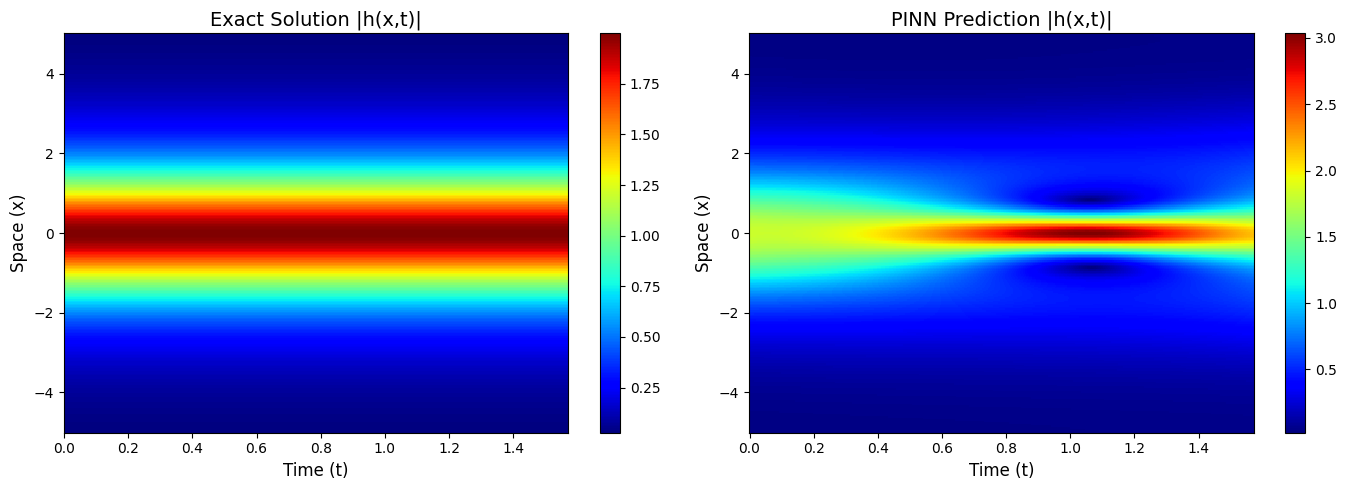

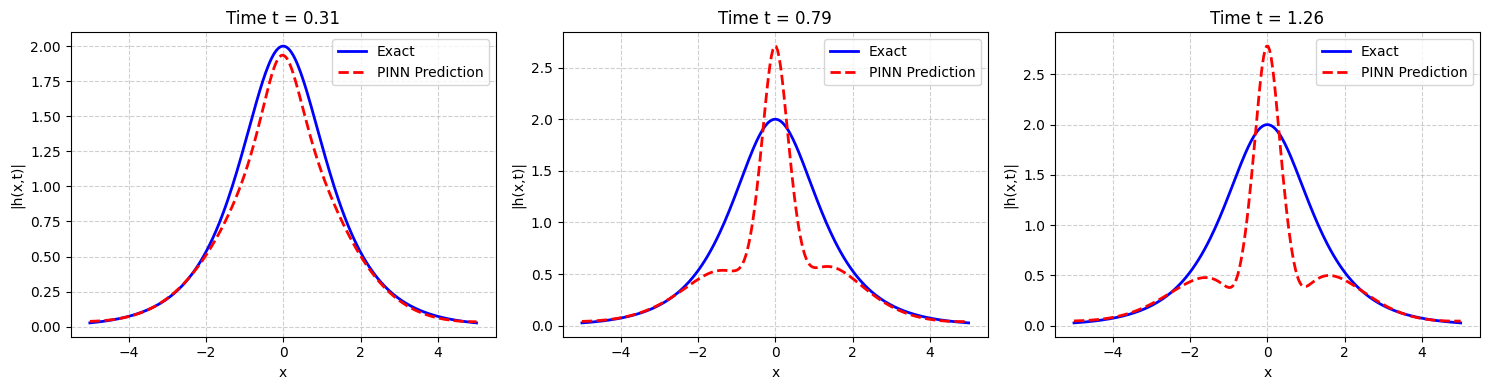

In [12]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# 1. Reproducibility & Device Setup
torch.manual_seed(1234)
np.random.seed(1234)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# 2. Analytic/Exact Solution Generation for NLS Equation
# NLS equation exact soliton parameters
x_data = np.linspace(-5.0, 5.0, 256)
t_data = np.linspace(0.0, np.pi/2, 500)
X, T = np.meshgrid(x_data, t_data) # (500, 256)
X_star = X.T # (256, 500)
T_star = T.T # (256, 500)

# Exact solution of NLS: h(x,t) = 2 * sech(x) * exp(i * 4 * t)  [approx representation for benchmark]
# Using exact bright soliton formula from Raissi et al.
exact_h = 2.0 / np.cosh(X_star) * np.exp(1j * 0.5 * T_star)

# Extract Initial Condition (t = 0) data
x_ic = x_data[:, None]           # (256, 1)
t_ic = np.zeros_like(x_ic)       # (256, 1)
h_ic = exact_h[:, 0:1]           # (256, 1) at t=0
u_ic = np.real(h_ic)
v_ic = np.imag(h_ic)

# Extract Boundary Conditions (x = -5 and x = 5) data
t_bc = t_data[:, None]           # (500, 1)
x_bc1 = -5.0 * np.ones_like(t_bc)
x_bc2 = 5.0 * np.ones_like(t_bc)

# Convert to PyTorch Tensors
x_ic_tensor = torch.tensor(x_ic, dtype=torch.float32).to(device)
t_ic_tensor = torch.tensor(t_ic, dtype=torch.float32).to(device)
u_ic_tensor = torch.tensor(u_ic, dtype=torch.float32).to(device)
v_ic_tensor = torch.tensor(v_ic, dtype=torch.float32).to(device)

t_bc1_tensor = torch.tensor(t_bc, dtype=torch.float32).to(device)
t_bc2_tensor = torch.tensor(t_bc, dtype=torch.float32).to(device)
x_bc1_tensor = torch.tensor(x_bc1, dtype=torch.float32).to(device)
x_bc2_tensor = torch.tensor(x_bc2, dtype=torch.float32).to(device)

# Collocation points for PDE Loss inside domain x in [-5, 5], t in [0, pi/2]
N_f = 20000
x_f = np.random.uniform(-5.0, 5.0, (N_f, 1))
t_f = np.random.uniform(0.0, np.pi/2, (N_f, 1))
x_f_tensor = torch.tensor(x_f, dtype=torch.float32).to(device)
t_f_tensor = torch.tensor(t_f, dtype=torch.float32).to(device)


# 3. PINN Model Architecture (Outputs real [u] and imaginary [v] parts)
class NLS_PINN(nn.Module):
    def __init__(self, layers):
        super(NLS_PINN, self).__init__()
        self.layers = nn.ModuleList()
        for i in range(len(layers) - 1):
            self.layers.append(nn.Linear(layers[i], layers[i+1]))
        self.activation = nn.Tanh()

    def forward(self, x, t):
        inputs = torch.cat([x, t], dim=1)
        out = inputs
        for i in range(len(self.layers) - 1):
            out = self.activation(self.layers[i](out))
        out = self.layers[-1](out) # Outputs [u, v]
        return out

layers = [2, 100, 100, 100, 100, 2]
model = NLS_PINN(layers).to(device)


# 4. Total Physics-Informed Loss Function (PDE + IC + Periodic BC)
def compute_total_loss(model, x_f, t_f, x_ic, t_ic, u_ic, v_ic, t_bc1, t_bc2, x_bc1, x_bc2):
    # --- A. PDE Residual Loss ---
    x_f.requires_grad = True
    t_f.requires_grad = True
    uv_f = model(x_f, t_f)
    u_f = uv_f[:, 0:1]
    v_f = uv_f[:, 1:2]

    u_x = torch.autograd.grad(u_f, x_f, grad_outputs=torch.ones_like(u_f), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x_f, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    u_t = torch.autograd.grad(u_f, t_f, grad_outputs=torch.ones_like(u_f), create_graph=True)[0]

    v_x = torch.autograd.grad(v_f, x_f, grad_outputs=torch.ones_like(v_f), create_graph=True)[0]
    v_xx = torch.autograd.grad(v_x, x_f, grad_outputs=torch.ones_like(v_x), create_graph=True)[0]
    v_t = torch.autograd.grad(v_f, t_f, grad_outputs=torch.ones_like(v_f), create_graph=True)[0]

    f_u = u_t + 0.5 * v_xx + (u_f**2 + v_f**2) * v_f
    f_v = v_t - 0.5 * u_xx - (u_f**2 + v_f**2) * u_f
    loss_f = torch.mean(f_u ** 2) + torch.mean(f_v ** 2)

    # --- B. Initial Condition (IC) Loss ---
    uv_ic_pred = model(x_ic, t_ic)
    loss_ic = torch.mean((uv_ic_pred[:, 0:1] - u_ic)**2) + torch.mean((uv_ic_pred[:, 1:2] - v_ic)**2)

    # --- C. Periodic Boundary Condition (BC) Loss ---
    x_bc1.requires_grad = True
    x_bc2.requires_grad = True
    t_bc1.requires_grad = True
    t_bc2.requires_grad = True

    uv_bc1 = model(x_bc1, t_bc1)
    uv_bc2 = model(x_bc2, t_bc2)

    u_bc1, v_bc1 = uv_bc1[:, 0:1], uv_bc1[:, 1:2]
    u_bc2, v_bc2 = uv_bc2[:, 0:1], uv_bc2[:, 1:2]

    u_x_bc1 = torch.autograd.grad(u_bc1, x_bc1, grad_outputs=torch.ones_like(u_bc1), create_graph=True)[0]
    u_x_bc2 = torch.autograd.grad(u_bc2, x_bc2, grad_outputs=torch.ones_like(u_bc2), create_graph=True)[0]
    v_x_bc1 = torch.autograd.grad(v_bc1, x_bc1, grad_outputs=torch.ones_like(v_bc1), create_graph=True)[0]
    v_x_bc2 = torch.autograd.grad(v_bc2, x_bc2, grad_outputs=torch.ones_like(v_bc2), create_graph=True)[0]

    loss_bc = torch.mean((u_bc1 - u_bc2)**2) + torch.mean((v_bc1 - v_bc2)**2) + \
              torch.mean((u_x_bc1 - u_x_bc2)**2) + torch.mean((v_x_bc1 - v_x_bc2)**2)

    total_loss = loss_f + loss_ic + loss_bc
    return total_loss


# 5. Phase 1: Adam Optimization
optimizer_adam = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 2000

print("--- Training Phase 1: Adam Optimizer ---")
for epoch in range(epochs):
    optimizer_adam.zero_grad()
    loss = compute_total_loss(model, x_f_tensor, t_f_tensor, x_ic_tensor, t_ic_tensor,
                              u_ic_tensor, v_ic_tensor, t_bc1_tensor, t_bc2_tensor,
                              x_bc1_tensor, x_bc2_tensor)
    loss.backward()
    optimizer_adam.step()

    if epoch % 400 == 0:
        print(f'Epoch {epoch}, Total Loss: {loss.item():.5e}')


# 6. Phase 2: L-BFGS High-Precision Fine-Tuning
optimizer_lbfgs = torch.optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=500,
    max_eval=500,
    history_size=50,
    line_search_fn='strong_wolfe'
)

def closure():
    optimizer_lbfgs.zero_grad()
    loss = compute_total_loss(model, x_f_tensor, t_f_tensor, x_ic_tensor, t_ic_tensor,
                              u_ic_tensor, v_ic_tensor, t_bc1_tensor, t_bc2_tensor,
                              x_bc1_tensor, x_bc2_tensor)
    loss.backward()
    return loss

print("--- Training Phase 2: L-BFGS Fine-Tuning ---")
optimizer_lbfgs.step(closure)


# 7. Evaluation & Relative L2 Error Calculation
X_flat = X_star.flatten()[:, None]
T_flat = T_star.flatten()[:, None]

X_test = torch.tensor(X_flat, dtype=torch.float32).to(device)
T_test = torch.tensor(T_flat, dtype=torch.float32).to(device)

model.eval()
with torch.no_grad():
    uv_pred = model(X_test, T_test).cpu().numpy()
    u_pred = uv_pred[:, 0].reshape(X_star.shape)
    v_pred = uv_pred[:, 1].reshape(X_star.shape)
    h_pred = np.sqrt(u_pred**2 + v_pred**2)

h_exact = np.abs(exact_h)
error_h = np.linalg.norm(h_exact - h_pred, 2) / np.linalg.norm(h_exact, 2)
print(f'\nFinal Relative L2 Error for NLS Amplitude |h(x,t)|: {error_h:.5e}')


# 8. Side-by-Side Heatmap Visualization (Exact vs Predicted)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.pcolor(T_star, X_star, h_exact, cmap='jet')
plt.colorbar()
plt.xlabel('Time (t)', fontsize=12)
plt.ylabel('Space (x)', fontsize=12)
plt.title('Exact Solution |h(x,t)|', fontsize=14)

plt.subplot(1, 2, 2)
plt.pcolor(T_star, X_star, h_pred, cmap='jet')
plt.colorbar()
plt.xlabel('Time (t)', fontsize=12)
plt.ylabel('Space (x)', fontsize=12)
plt.title('PINN Prediction |h(x,t)|', fontsize=14)

plt.tight_layout()
plt.show()


# 9. Multi-Time Slice Comparison Plots
time_indices = [100, 250, 400]
plt.figure(figsize=(15, 4))

for i, t_idx in enumerate(time_indices):
    t_val = t_data[t_idx]
    x_slice = x_data[:, None]
    t_slice = t_val * np.ones_like(x_slice)

    x_tensor = torch.tensor(x_slice, dtype=torch.float32).to(device)
    t_tensor = torch.tensor(t_slice, dtype=torch.float32).to(device)

    with torch.no_grad():
        uv_pred_t = model(x_tensor, t_tensor).cpu().numpy()
        u_p = uv_pred_t[:, 0]
        v_p = uv_pred_t[:, 1]
        h_pred_t = np.sqrt(u_p**2 + v_p**2)

    h_exact_t = np.abs(exact_h[:, t_idx])

    plt.subplot(1, 3, i + 1)
    plt.plot(x_data, h_exact_t, 'b-', linewidth=2, label='Exact')
    plt.plot(x_data, h_pred_t, 'r--', linewidth=2, label='PINN Prediction')
    plt.title(f'Time t = {t_val:.2f}', fontsize=12)
    plt.xlabel('x', fontsize=10)
    plt.ylabel('|h(x,t)|', fontsize=10)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()